# ClinicSense – Notebook 01: Data Collection & Exploratory Data Analysis
**B.Sc. Data Science Honours | Student: Kadam Akanksha Dinkar**

This notebook covers:
- Phase 2: Data Collection and Understanding
- Phase 3: EDA and Statistical Analysis

**Inter-notebook dependencies:** None (this is the first notebook).

**Outputs written:** `data/processed_data_eda.csv` (optional snapshot for reference)

---

## 1. Setup and Data Loading

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11
sns.set_theme(style='whitegrid', palette='Set2')

from src.data_loader import load_raw, dataset_summary
from src.config import FIGURES_DIR
import warnings
warnings.filterwarnings('ignore')
os.makedirs(FIGURES_DIR, exist_ok=True)

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [2]:
# ── DATASET REQUIREMENT ───────────────────────────────────────────────────────
# Download KaggleV2-May-2016.csv from:
# https://www.kaggle.com/datasets/joniarroba/noshowappointments
# Place it in the data/ folder before running this cell.
df = load_raw()
dataset_summary(df)
df.head()

[DataLoader] Removed 38568 invalid records (110527 → 71959).
DATASET SUMMARY
Shape          : 71,959 rows × 14 columns
Date range     : 2016-04-29 → 2016-06-08
Unique patients: 45,840
No-show count  : 20,522  (28.5%)
Show count     : 51,437  (71.5%)

Column dtypes:
patient_id                float64
appointment_id              int64
gender                     object
scheduled_day      datetime64[ns]
appointment_day    datetime64[ns]
age                         int64
neighbourhood              object
scholarship                  int8
hypertension                 int8
diabetes                     int8
alcoholism                   int8
handicap                     int8
sms_received                 int8
no_show                     int32
dtype: object

Missing values:
  None


,patient_id,appointment_id,gender,scheduled_day,appointment_day,age,neighbourhood,scholarship,hypertension,diabetes,alcoholism,handicap,sms_received,no_show
0,9.598513e+13,5626772,F,2016-04-27 08:36:51,2016-04-29,76,REPÚBLICA,0,1,0,0,0,0,0
1,7.336882e+14,5630279,F,2016-04-27 15:05:12,2016-04-29,23,GOIABEIRAS,0,0,0,0,0,0,1
2,3.449833e+12,5630575,F,2016-04-27 15:39:58,2016-04-29,39,GOIABEIRAS,0,0,0,0,0,0,1
3,7.812456e+13,5629123,F,2016-04-27 12:48:25,2016-04-29,19,CONQUISTA,0,0,0,0,0,0,0
4,7.345362e+14,5630213,F,2016-04-27 14:58:11,2016-04-29,30,NOVA PALESTINA,0,0,0,0,0,0,0


## 2. Dataset Overview

In [3]:
print('Shape:', df.shape)
print('\nColumn Types:')
print(df.dtypes)
print('\nBasic Statistics:')
df.describe(include='all').T

Shape: (71959, 14)

Column Types:
patient_id                float64
appointment_id              int64
gender                     object
scheduled_day      datetime64[ns]
appointment_day    datetime64[ns]
age                         int64
neighbourhood              object
scholarship                  int8
hypertension                 int8
diabetes                     int8
alcoholism                   int8
handicap                     int8
sms_received                 int8
no_show                     int32
dtype: object

Basic Statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
patient_id,71959.0,NaN,NaN,NaN,145260553785481.625,39217.84439,3968098591204.0,29918914113934.0,93716598086343.0,999931985292928.0,253566723982050.1875
appointment_id,71959.0,NaN,NaN,NaN,5655041.617379,5030230.0,5617795.5,5661165.0,5707178.0,5784985.0,74721.894747
gender,71959,2,F,48070,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scheduled_day,71959,NaN,NaN,NaN,2016-05-03 21:52:55.724343296,2015-11-10 07:13:56,2016-04-25 17:17:23,2016-05-05 07:15:45,2016-05-17 09:17:09,2016-06-07 19:03:57,NaN
appointment_day,71959,NaN,NaN,NaN,2016-05-19 01:43:02.320487936,2016-04-29 00:00:00,2016-05-09 00:00:00,2016-05-18 00:00:00,2016-05-31 00:00:00,2016-06-08 00:00:00,NaN
age,71959.0,NaN,NaN,NaN,38.502564,0.0,19.0,39.0,57.0,115.0,22.925421
neighbourhood,71959,80,JARDIM CAMBURI,5213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scholarship,71959.0,NaN,NaN,NaN,0.092706,0.0,0.0,0.0,0.0,1.0,0.290021
hypertension,71959.0,NaN,NaN,NaN,0.208897,0.0,0.0,0.0,0.0,1.0,0.406523
diabetes,71959.0,NaN,NaN,NaN,0.074723,0.0,0.0,0.0,0.0,1.0,0.262946


## 3. Target Variable – Class Imbalance

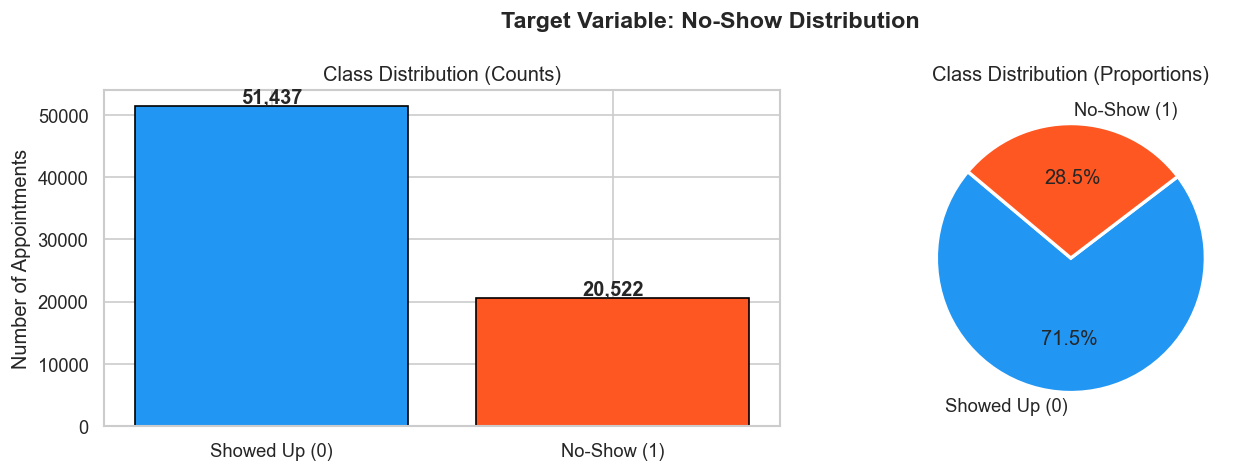

No-show rate: 28.52%
The dataset is imbalanced (~20% no-shows). Models must account for this.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df['no_show'].value_counts()
labels = ['Showed Up (0)', 'No-Show (1)']

axes[0].bar(labels, counts.values, color=['#2196F3','#FF5722'], edgecolor='black')
axes[0].set_title('Class Distribution (Counts)')
axes[0].set_ylabel('Number of Appointments')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(counts.values, labels=labels, autopct='%1.1f%%',
            colors=['#2196F3','#FF5722'], startangle=140,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Class Distribution (Proportions)')

plt.suptitle('Target Variable: No-Show Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/class_distribution.png', dpi=150)
plt.show()

print(f'No-show rate: {df["no_show"].mean()*100:.2f}%')
print('The dataset is imbalanced (~20% no-shows). Models must account for this.')

## 4. Age Distribution Analysis

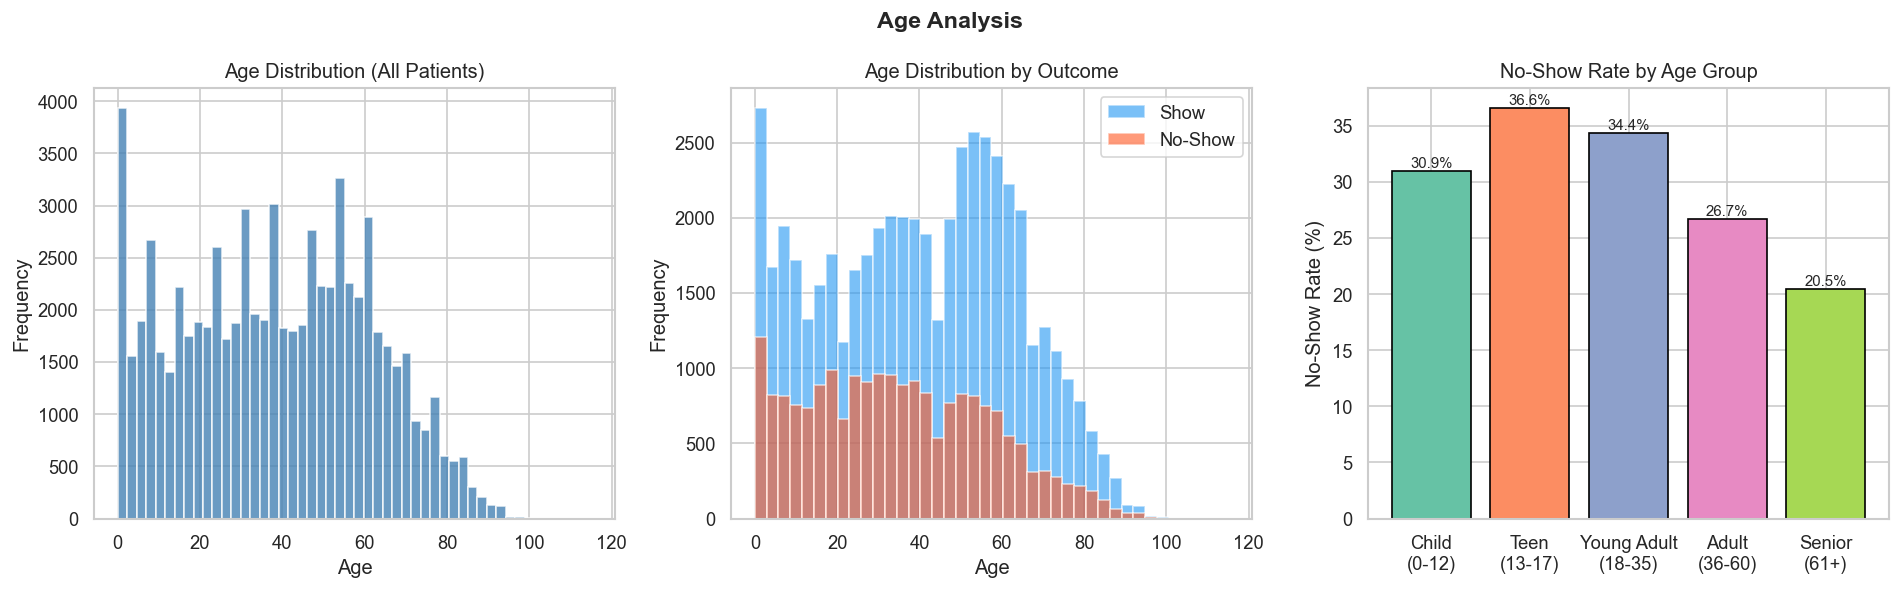

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].hist(df['age'], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_title('Age Distribution (All Patients)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

df[df['no_show']==0]['age'].plot.hist(bins=40, ax=axes[1], alpha=0.6,
                                      color='#2196F3', label='Show')
df[df['no_show']==1]['age'].plot.hist(bins=40, ax=axes[1], alpha=0.6,
                                      color='#FF5722', label='No-Show')
axes[1].set_title('Age Distribution by Outcome')
axes[1].set_xlabel('Age')
axes[1].legend()

bins   = [0, 12, 17, 35, 60, 115]
labels = ['Child\n(0-12)', 'Teen\n(13-17)', 'Young Adult\n(18-35)',
          'Adult\n(36-60)', 'Senior\n(61+)']
df['age_grp'] = pd.cut(df['age'], bins=bins, labels=labels, include_lowest=True)
ns_by_age = df.groupby('age_grp', observed=True)['no_show'].mean() * 100
axes[2].bar(ns_by_age.index, ns_by_age.values, color=sns.color_palette('Set2', 5),
            edgecolor='black')
axes[2].set_title('No-Show Rate by Age Group')
axes[2].set_ylabel('No-Show Rate (%)')
for i, v in enumerate(ns_by_age.values):
    axes[2].text(i, v + 0.3, f'{v:.1f}%', ha='center', fontsize=9)

plt.suptitle('Age Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/age_analysis.png', dpi=150)
plt.show()

## 5. Temporal Analysis – Weekday, Month, Lead Time

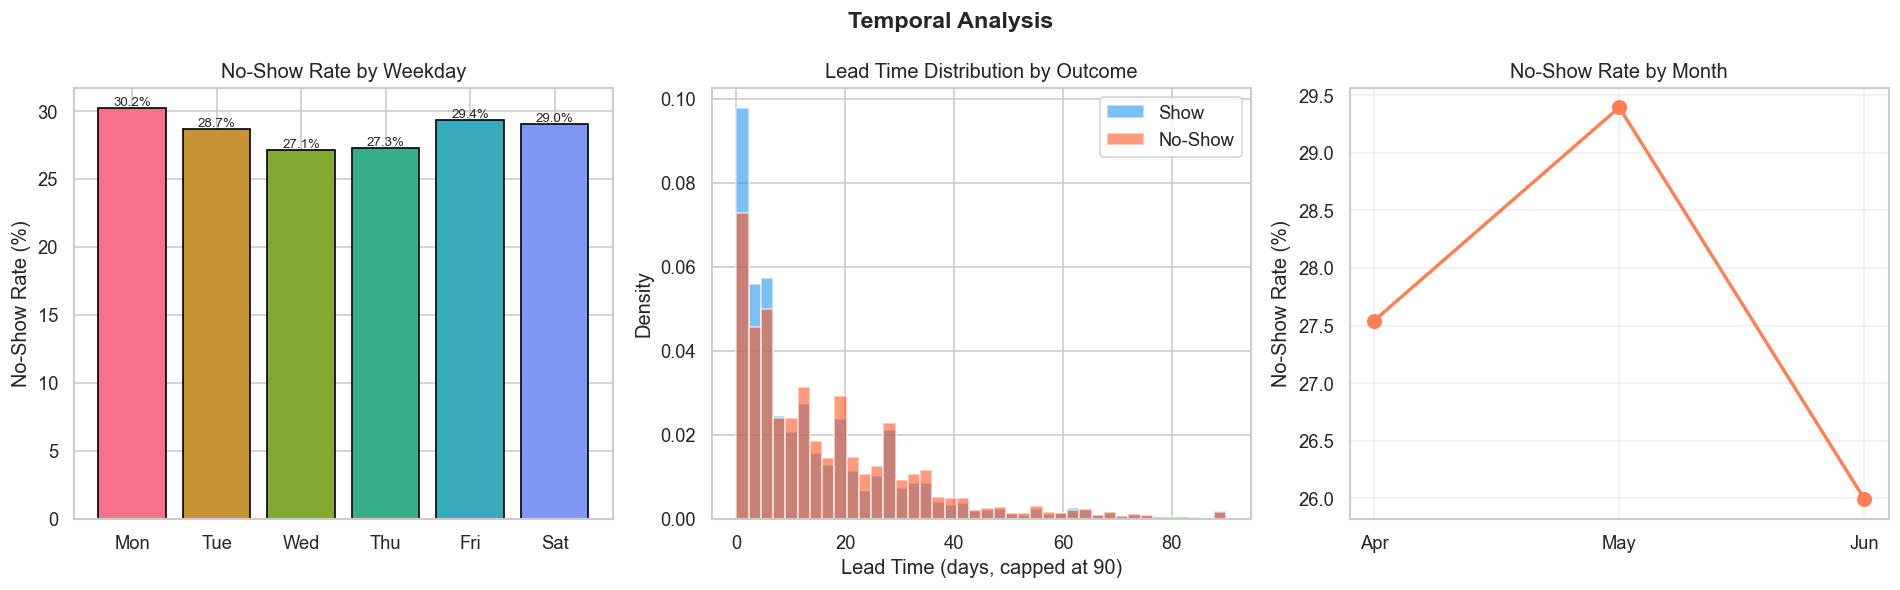

In [6]:
df['appt_weekday']   = df['appointment_day'].dt.dayofweek
df['appt_month']     = df['appointment_day'].dt.month
df['lead_time_days'] = ((df['appointment_day'] - df['scheduled_day'])
                        .dt.total_seconds() / 86400).clip(lower=0).astype(int)

day_names = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ns_weekday = df.groupby('appt_weekday')['no_show'].mean() * 100
axes[0].bar([day_names[i] for i in ns_weekday.index], ns_weekday.values,
            color=sns.color_palette('husl', 7), edgecolor='black')
axes[0].set_title('No-Show Rate by Weekday')
axes[0].set_ylabel('No-Show Rate (%)')
for i, v in enumerate(ns_weekday.values):
    axes[0].text(i, v+0.2, f'{v:.1f}%', ha='center', fontsize=8)

lead_capped = df['lead_time_days'].clip(upper=90)
axes[1].hist(lead_capped[df['no_show']==0], bins=40, alpha=0.6,
             color='#2196F3', label='Show', density=True)
axes[1].hist(lead_capped[df['no_show']==1], bins=40, alpha=0.6,
             color='#FF5722', label='No-Show', density=True)
axes[1].set_title('Lead Time Distribution by Outcome')
axes[1].set_xlabel('Lead Time (days, capped at 90)')
axes[1].set_ylabel('Density')
axes[1].legend()

month_names = ['Jan','Feb','Mar','Apr','May','Jun']
ns_month = df.groupby('appt_month')['no_show'].mean() * 100
axes[2].plot(range(len(ns_month)), ns_month.values, marker='o',
             color='coral', linewidth=2, markersize=8)
axes[2].set_xticks(range(len(ns_month)))
axes[2].set_xticklabels([month_names[i-1] for i in ns_month.index])
axes[2].set_title('No-Show Rate by Month')
axes[2].set_ylabel('No-Show Rate (%)')
axes[2].grid(True, alpha=0.3)

plt.suptitle('Temporal Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/temporal_analysis.png', dpi=150)
plt.show()

## 6. SMS Reminder Effect

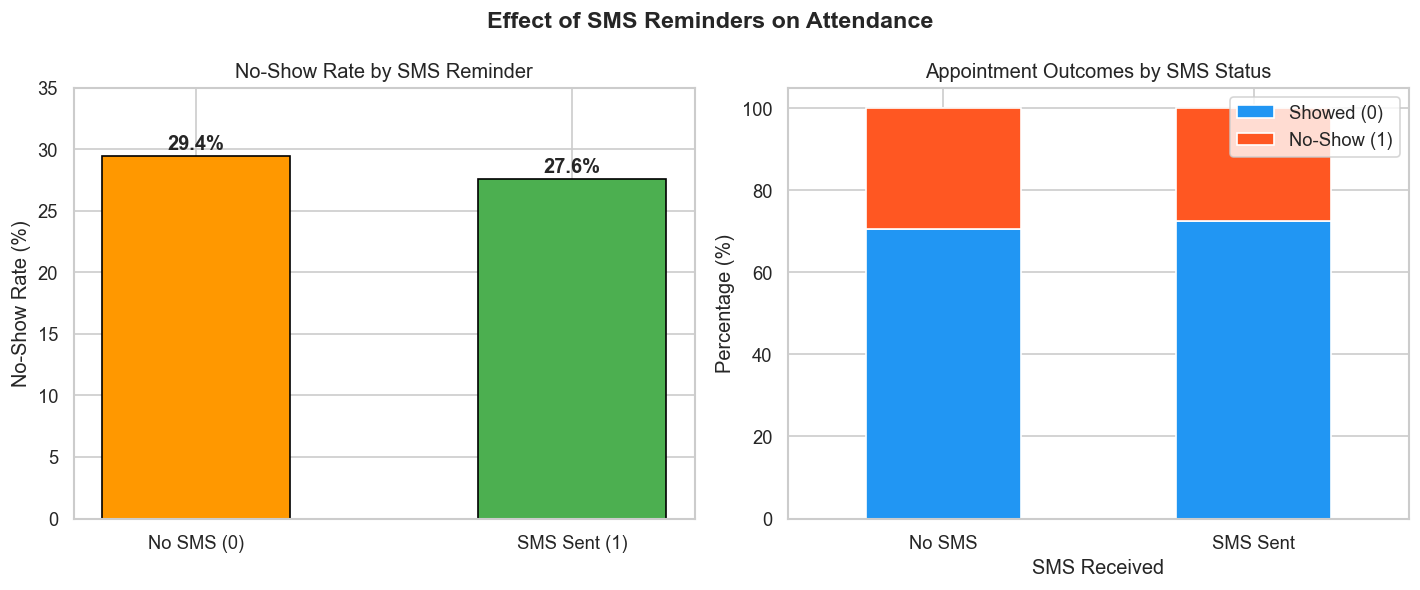

Chi-square test (SMS vs No-Show):
  χ² = 30.54, df = 1, p-value = 3.2750e-08
  Result: Statistically significant (α=0.05)


In [7]:
sms_ns = df.groupby('sms_received')['no_show'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

bars = axes[0].bar(['No SMS (0)', 'SMS Sent (1)'], sms_ns.values,
                    color=['#FF9800','#4CAF50'], edgecolor='black', width=0.5)
axes[0].set_title('No-Show Rate by SMS Reminder')
axes[0].set_ylabel('No-Show Rate (%)')
axes[0].set_ylim(0, 35)
for bar, v in zip(bars, sms_ns.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, v+0.5,
                 f'{v:.1f}%', ha='center', fontweight='bold', fontsize=12)

crosstab = pd.crosstab(df['sms_received'], df['no_show'], normalize='index') * 100
crosstab.plot(kind='bar', stacked=True, ax=axes[1],
              color=['#2196F3','#FF5722'], edgecolor='white')
axes[1].set_title('Appointment Outcomes by SMS Status')
axes[1].set_xlabel('SMS Received')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xticklabels(['No SMS','SMS Sent'], rotation=0)
axes[1].legend(['Showed (0)','No-Show (1)'], loc='upper right')

plt.suptitle('Effect of SMS Reminders on Attendance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/sms_analysis.png', dpi=150)
plt.show()

ct = pd.crosstab(df['sms_received'], df['no_show'])
chi2, p_val, dof, _ = stats.chi2_contingency(ct)
print(f'Chi-square test (SMS vs No-Show):')
print(f'  χ² = {chi2:.2f}, df = {dof}, p-value = {p_val:.4e}')
print(f'  Result: {"Statistically significant" if p_val < 0.05 else "Not significant"} (α=0.05)')

## 7. Chronic Conditions Analysis

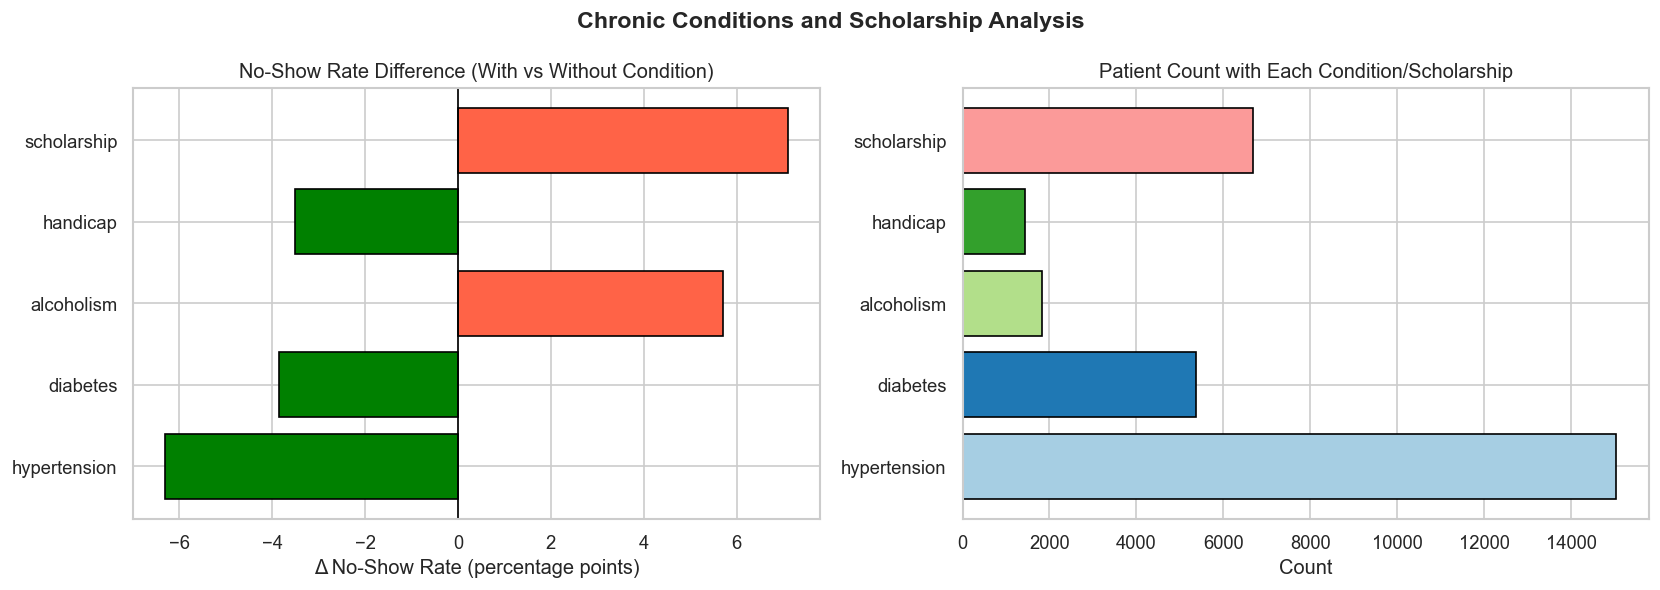

In [8]:
conditions = ['hypertension', 'diabetes', 'alcoholism', 'handicap', 'scholarship']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cond_ns = {c: df.groupby(c)['no_show'].mean()*100 for c in conditions}
cond_diff = pd.Series({c: cond_ns[c].get(1, 0) - cond_ns[c].get(0, 0)
                        for c in conditions})
colors = ['green' if v < 0 else 'tomato' for v in cond_diff.values]
axes[0].barh(cond_diff.index, cond_diff.values, color=colors, edgecolor='black')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_title('No-Show Rate Difference (With vs Without Condition)')
axes[0].set_xlabel('Δ No-Show Rate (percentage points)')

cond_counts = df[conditions].sum()
axes[1].barh(cond_counts.index, cond_counts.values,
             color=sns.color_palette('Paired', 5), edgecolor='black')
axes[1].set_title('Patient Count with Each Condition/Scholarship')
axes[1].set_xlabel('Count')

plt.suptitle('Chronic Conditions and Scholarship Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/conditions_analysis.png', dpi=150)
plt.show()

## 8. Correlation Matrix

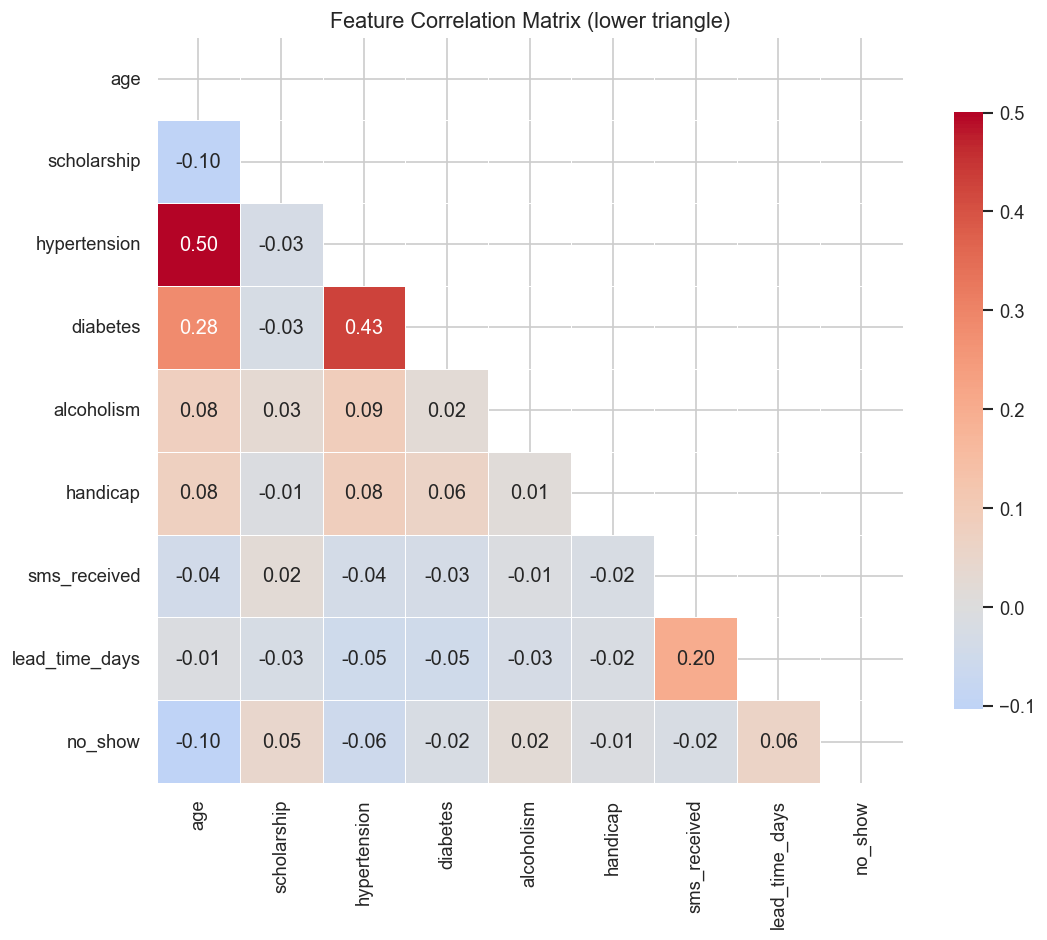


Correlations with no_show target:
age              -0.1010
lead_time_days    0.0604
hypertension     -0.0569
scholarship       0.0457
diabetes         -0.0224
sms_received     -0.0206
alcoholism        0.0199
handicap         -0.0072
Name: no_show, dtype: float64


In [9]:
numeric_cols = ['age', 'scholarship', 'hypertension', 'diabetes', 'alcoholism',
                'handicap', 'sms_received', 'lead_time_days', 'no_show']
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, mask=mask, ax=ax,
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Matrix (lower triangle)', fontsize=13)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/correlation_matrix.png', dpi=150)
plt.show()

print('\nCorrelations with no_show target:')
target_corr = corr['no_show'].drop('no_show').sort_values(key=abs, ascending=False)
print(target_corr.round(4))

## 9. Hypothesis Testing

In [10]:
print('='*65)
print('HYPOTHESIS TESTS')
print('='*65)

# H1: Lead time differs between no-shows and shows
show_lead   = df[df['no_show']==0]['lead_time_days']
noshow_lead = df[df['no_show']==1]['lead_time_days']
t_stat, p_val = stats.mannwhitneyu(show_lead, noshow_lead, alternative='two-sided')
print(f'\nH1: Lead time differs between shows and no-shows')
print(f'  Mann-Whitney U = {t_stat:.0f}, p = {p_val:.4e}')
print(f'  Mean lead time - Show: {show_lead.mean():.1f}d | No-Show: {noshow_lead.mean():.1f}d')
print(f'  → {"Reject H0" if p_val < 0.05 else "Fail to reject H0"}')

# H2: Age differs between no-shows and shows
show_age   = df[df['no_show']==0]['age']
noshow_age = df[df['no_show']==1]['age']
t_stat2, p_val2 = stats.mannwhitneyu(show_age, noshow_age, alternative='two-sided')
print(f'\nH2: Age differs between shows and no-shows')
print(f'  Mann-Whitney U = {t_stat2:.0f}, p = {p_val2:.4e}')
print(f'  Mean age - Show: {show_age.mean():.1f} | No-Show: {noshow_age.mean():.1f}')
print(f'  → {"Reject H0" if p_val2 < 0.05 else "Fail to reject H0"}')

# H3: SMS affects no-show rate (Chi-square)
ct_sms = pd.crosstab(df['sms_received'], df['no_show'])
chi2, p_sms, dof, _ = stats.chi2_contingency(ct_sms)
print(f'\nH3: SMS reminder is associated with no-show rate')
print(f'  χ²({dof}) = {chi2:.2f}, p = {p_sms:.4e}')
print(f'  → {"Reject H0" if p_sms < 0.05 else "Fail to reject H0"}')

print('\n' + '='*65)

HYPOTHESIS TESTS

H1: Lead time differs between shows and no-shows
  Mann-Whitney U = 468763975, p = 4.9752e-122
  Mean lead time - Show: 14.0d | No-Show: 16.2d
  → Reject H0

H2: Age differs between shows and no-shows
  Mann-Whitney U = 597981170, p = 2.7490e-171
  Mean age - Show: 40.0 | No-Show: 34.8
  → Reject H0

H3: SMS reminder is associated with no-show rate
  χ²(1) = 30.54, p = 3.2750e-08
  → Reject H0



## 10. EDA Summary

| Finding | Insight |
|---------|----------|
| Class imbalance | ~20% no-shows → SMOTE / class weights required in modelling |
| Lead time | No-show patients have significantly longer lead times (H1 confirmed) |
| Age | Age is significantly associated with outcome (H2 confirmed) |
| SMS reminder | SMS recipients have lower no-show rates (H3 confirmed) |
| Weekday | Mondays and Fridays show elevated no-show rates |
| Neighbourhood | Geographic variation in no-show rates exists |
| Chronic conditions | Diabetic/hypertensive patients show slightly lower no-show rates |

**Proceed to Notebook 02** for preprocessing and feature engineering.